# RSW / 04 — Burst reversion: enter against the burst when the regime switches back to calm (2021-01 – 2023-06)

Protocol: [`RSW 007`](../../discussions/MNQ_Regime_Switching/007_claude_rsw04_burst_reversion_preregistration.md). 1-minute fill simulation. Ticks per contract (1 tick = $0.50).

- **Entry**: at the first bar where the causal P(burst) ≤ 0.5 after a burst episode, against the episode's net move.
- **Exit**: at the time stop (the fit's mean calm duration + 5 bars), at a stop, or flat at 15:55 Chicago.
- **Strategies**: 2 regime models (M1 HMM, WB2 HSMM) × 5 stops (none, burst extreme + 2 ticks, 1.5σ̂, 3σ̂, 40 ticks) = 10.
- **Gates**:
  - **G1**: ≥ 150 trades.
  - **G2**: net > 0, Holm across 10 ≤ 0.05.
  - **G3**: net > 0 in ≥ 2 of 3 periods.
  - **G4**: beats the 95th percentile of the random-direction placebo (20 seeds).

In [1]:
import json, os, sys, tempfile, pickle
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RSW_SYNTHETIC") == "1"
SYNTH_NULL = os.environ.get("RSW_SYNTH_NULL") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RSW_SYNTH_DIR") or tempfile.mkdtemp(prefix="rsw_")
    os.environ["RSW_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import reversal as V
from equity_trading import regime_ar as R
from equity_trading import hsmm as HS
from equity_trading import burst_reversion as B
from equity_trading import trail_strategy as T
from equity_trading import micro_bars as MB

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
RC, HC, BC = R.RSWConfig(), HS.HSMMConfig(), B.BRConfig()
D = dt.date
OUT = Path("04"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_rows", 80)
print("engines", B.BR_VERSION, HS.HSMM_VERSION, R.RSW_VERSION, P.MRP_VERSION,
      ("| synthetic " + ("null" if SYNTH_NULL else "planted reversion")) if SYNTHETIC else "| real data",
      "| round trip", BC.round_trip_ticks, "ticks")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    B.write_synthetic_burst_reversion(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG,
                                      revert_frac=0.0 if SYNTH_NULL else 0.6)

engines 0.1.0 0.1.0 0.1.0 0.1.1 | real data | round trip 3.0 ticks


In [2]:
if SYNTHETIC:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2020Q3": (D(2020, 7, 1), D(2020, 9, 30)), "2020Q4": (D(2020, 10, 1), D(2020, 12, 31))}
else:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2021": (D(2021, 1, 1), D(2021, 12, 31)), "2022": (D(2022, 1, 1), D(2022, 12, 31)),
               "2023H1": (D(2023, 1, 1), D(2023, 6, 30))}
NEED_PERIODS = int(np.ceil(2 / 3 * len(PERIODS)))
grid = P.load_grid(CFG.warmup_start, END, CFG)
sig2 = V.event_sigma(grid, FIRST_FIT, REFITS, END, CFG)
m1 = MB.load_1m(CFG.root, CFG.warmup_start - dt.timedelta(days=3), END + dt.timedelta(days=1))
S = R.build_series(grid, sig2, m1, CFG, RC)
S["iid"] = grid["instrument_id"].reindex(S.index).to_numpy()
S = S[(S["trade_date"] >= CFG.train[0]) & (S["trade_date"] <= END)]
M = T.minutes_from_1m(m1[m1.index >= pd.Timestamp(REFITS[0] - dt.timedelta(days=2), tz="UTC")],
                      T.TrailConfig(flat_ct=BC.flat_ct, commission_per_side=BC.commission_per_side))
del m1, grid
td = S["trade_date"].to_numpy()
print(f"{len(S):,} bars | {len(M.ts):,} minutes from {M.ts[0]}")

243,984 bars | 856,743 minutes from 2020-12-30 00:00:00+00:00


## 1. Walk-forward regime fits and burst probabilities

In [3]:
cache = OUT / f"fits_{B.BR_VERSION}{'_synth' if SYNTHETIC else ''}{'_null' if SYNTH_NULL else ''}.pkl"
FITS = pickle.load(open(cache, "rb")) if cache.exists() else {}
for a in REFITS:
    fm = td < a
    if ("M1", str(a)) not in FITS:
        t0 = dt.datetime.now(); FITS[("M1", str(a))] = R.fit(S, 2, False, fm, RC)
        pickle.dump(FITS, open(cache, "wb")); print("M1 before", a, dt.datetime.now() - t0)
    if ("WB2", str(a)) not in FITS:
        t0 = dt.datetime.now(); FITS[("WB2", str(a))] = HS.fit(S, fm, FITS[("M1", str(a))], "WB", False, HC)
        pickle.dump(FITS, open(cache, "wb")); print("WB2 before", a, dt.datetime.now() - t0)
edges = list(REFITS) + [END + dt.timedelta(days=1)]
PB, HOLD, info = {}, {}, []
for name in ("M1", "WB2"):
    pb, hold = np.full(len(S), np.nan), np.zeros(len(S), int)
    for a, b in zip(edges[:-1], edges[1:]):
        f = FITS[(name, str(a))]
        seg = (td >= a) & (td < b)
        if name == "M1":
            p = R.filter_run(S, f)[[f"p{k}" for k in range(2)]].to_numpy()
            burst = int(np.argmax(f.s2)); calm = 1 - burst
            mean_calm = 1 / (1 - f.A[calm, calm])
        else:
            p = HS.filter_run(S, f, 2.0)[[f"p{k}" for k in range(2)]].to_numpy()
            burst = int(np.argmax(f.s2)); calm = 1 - burst
            mean_calm = f.mean_duration(calm)
        pb[seg] = p[seg, burst]
        hold[seg] = int(round(mean_calm)) + BC.extra_bars
        info.append({"model": name, "fit_before": str(a), "burst_sd": float(np.sqrt(f.s2[burst])), "calm_sd": float(np.sqrt(f.s2[calm])),
                     "burst_phi": float(f.phi[burst]), "calm_phi": float(f.phi[calm]), "mean_calm_bars": mean_calm,
                     "hold_bars": int(round(mean_calm)) + BC.extra_bars, "share_pb_gt_0.5": float(np.mean(pb[seg] > BC.p_burst))})
    PB[name], HOLD[name] = pb, hold
display(pd.DataFrame(info).round(4))

M1 before 2021-01-01 0:00:09.571815
WB2 before 2021-01-01 0:00:14.710875
M1 before 2022-01-01 0:00:16.934940
WB2 before 2022-01-01 0:00:28.795797
M1 before 2023-01-01 0:00:19.338062
WB2 before 2023-01-01 0:00:33.830200


,model,fit_before,burst_sd,calm_sd,burst_phi,calm_phi,mean_calm_bars,hold_bars,share_pb_gt_0.5
0,M1,2021-01-01,1.8739,0.8214,0.1728,-0.0579,12.3389,17,0.0411
1,M1,2022-01-01,1.8801,0.8042,0.1237,-0.0530,12.7330,18,0.0423
2,M1,2023-01-01,2.1049,0.8226,0.1341,-0.0421,16.2076,21,0.0324
3,WB2,2021-01-01,1.8388,0.8140,0.1745,-0.0556,10.2269,15,0.0463
4,WB2,2022-01-01,1.8387,0.7941,0.1464,-0.0549,9.7791,15,0.0470
5,WB2,2023-01-01,2.0629,0.8152,0.1502,-0.0429,13.3368,18,0.0353


In [4]:
EV = {name: B.episodes(S, PB[name], HOLD[name], BC) for name in ("M1", "WB2")}
for name, ev in EV.items():
    print(f"--- {name}: {len(ev)} episodes ending in a tradable switch | long (after down burst) {int((ev.side > 0).sum())}, "
          f"short {int((ev.side < 0).sum())}")
    display(ev[["burst_bars", "burst_move_ticks", "hold_bars"]].describe(percentiles=[.1, .5, .9]).round(1).T)

--- M1: 5561 episodes ending in a tradable switch | long (after down burst) 3427, short 2134


,count,mean,std,min,10%,50%,90%,max
burst_bars,5561.0,1.2,0.5,1.0,1.0,1.0,2.0,6.0
burst_move_ticks,5561.0,-29.0,154.9,-1614.0,-182.0,-48.0,132.0,1443.0
hold_bars,5561.0,18.1,1.4,17.0,17.0,18.0,21.0,21.0


--- WB2: 6252 episodes ending in a tradable switch | long (after down burst) 3860, short 2392


,count,mean,std,min,10%,50%,90%,max
burst_bars,6252.0,1.2,0.6,1.0,1.0,1.0,2.0,8.0
burst_move_ticks,6252.0,-28.5,152.8,-1614.0,-179.0,-47.0,133.0,1443.0
hold_bars,6252.0,15.5,1.1,15.0,15.0,15.0,18.0,18.0


## 2. Strategies: 2 models × 5 stops, with placebo and mirror

In [5]:
rows, TR = [], {}
for name, ev in EV.items():
    for kind in BC.stops:
        tr = B.simulate(M, ev, S.index, kind, BC)
        TR[(name, kind)] = tr
        st = B.stats_for(tr, PERIODS)
        plac = []
        for seed in range(BC.n_placebo):
            sides = np.random.default_rng(seed).choice([-1, 1], len(ev))
            pt = B.simulate(M, ev, S.index, kind, BC, sides=sides)
            plac.append(pt["net_ticks"].mean() if len(pt) else np.nan)
        mir = B.stats_for(B.simulate(M, ev, S.index, kind, BC, sides=-ev["side"].to_numpy()), PERIODS)
        rows.append({"model": name, "stop": kind, **st, "placebo_mean": float(np.nanmean(plac)),
                     "placebo_p95": float(np.nanquantile(plac, 0.95)), "mirror_net": mir["net"], "mirror_t": mir["t"]})
        print(name, kind, "trades", st["trades"], "net", round(st["net"], 2) if st["trades"] >= 3 else None)
G = pd.DataFrame(rows).set_index(["model", "stop"])
G["p_holm"] = pd.Series(R.holm({k: v for k, v in G["p"].fillna(1.0).items()}))
G["periods_pos"] = sum((G[f"net_{p}"] > 0).astype(int) for p in PERIODS)
G["G1"] = G["trades"] >= BC.min_trades
G["G2"] = (G["net"] > 0) & (G["p_holm"] <= BC.alpha)
G["G3"] = G["periods_pos"] >= NEED_PERIODS
G["G4"] = G["net"] > G["placebo_p95"]
G["pass"] = G[["G1", "G2", "G3", "G4"]].all(axis=1)
display(G.round(3).T)

M1 none trades 3483 net -2.26
M1 extreme trades 5072 net -2.77
M1 vol1.5 trades 4799 net -1.1
M1 vol3 trades 4351 net -1.6
M1 fixed40 trades 4883 net -1.77
WB2 none trades 3801 net -1.13
WB2 extreme trades 5609 net -3.08
WB2 vol1.5 trades 5259 net -1.01
WB2 vol3 trades 4720 net -1.92
WB2 fixed40 trades 5391 net -1.95


model              M1                                          WB2                                    
stop             none  extreme   vol1.5     vol3  fixed40     none  extreme   vol1.5     vol3  fixed40
trades           3483     5072     4799     4351     4883     3801     5609     5259     4720     5391
gross          -0.261   -0.774    0.899    0.402    0.229    0.873   -1.085    0.994    0.085    0.053
net            -2.261   -2.774   -1.101   -1.598   -1.771   -1.127   -3.085   -1.006   -1.915   -1.947
t              -0.561   -1.849   -0.528   -0.578   -1.143   -0.325   -2.287   -0.529   -0.747   -1.407
p               0.712    0.968    0.701    0.718    0.873    0.627    0.989    0.702    0.772     0.92
win_rate        0.511    0.154     0.27    0.412    0.222    0.517    0.157    0.284    0.428    0.231
mean_win      142.175  158.073  166.231  149.362  137.806  131.417  149.569  157.889  139.452  129.879
mean_loss    -153.055   -32.05  -62.877 -107.311  -41.645 -142.985  -31.606  -63.999 -107.771   -41.45
total_ticks   -7876.0 -14071.0  -5281.5  -6952.5  -8649.0  -4285.0 -17302.0  -5291.5  -9040.5 -10495.5
total_usd_1c  -3938.0  -7035.5 -2640.75 -3476.25  -4324.5  -2142.5  -8651.0 -2645.75 -4520.25 -5247.75
max_dd_ticks  20238.0  15327.0  14660.0  14475.5  12144.5  13335.0  18691.0  12752.5  11380.5  12823.0
worst         -1947.0   -454.5   -429.5   -845.5   -299.0  -1793.0   -454.5   -429.5   -845.5   -299.0
q05            -360.8  -94.725   -130.5   -225.5    -42.5   -333.0    -96.5   -131.5   -225.5    -42.5
exit_stop         0.0    0.829    0.706    0.473    0.752      0.0    0.823    0.687    0.448     0.74
exit_time       0.948    0.154    0.265    0.488    0.222    0.955    0.162    0.288    0.517    0.236
exit_flat       0.052    0.018    0.028    0.039    0.026    0.045    0.015    0.025    0.035    0.024
mean_minutes   87.488   23.156   38.839   60.881   32.697   75.315   20.669   35.572   54.478   29.524
net_long       -1.131    -2.45   -1.429   -1.193   -3.268   -2.811   -2.736   -1.244   -3.332   -2.802
net_short      -4.011   -3.314    -0.54   -2.286    0.773    1.534   -3.677   -0.588    0.556    -0.46
n_long           2116     3169     3026     2740     3074     2328     3530     3352     3000     3423
n_short          1367     1903     1773     1611     1809     1473     2079     1907     1720     1968
net_2021        2.289   -4.204   -0.067   -0.528   -0.325    2.763    -4.32   -0.661   -3.129   -0.473
net_2022       -2.318     0.28      0.0   -0.233   -0.555    0.462   -1.064   -0.149    1.347   -1.486
net_2023H1    -13.375   -6.249   -6.101   -7.336   -8.044  -14.684    -4.81   -3.869     -6.5   -6.625
placebo_mean   -1.732   -1.605   -0.445    0.574   -1.373   -3.246    -2.49   -1.104   -1.682   -1.981
placebo_p95     4.099    0.553    1.861     3.16    0.403    1.943   -0.911    0.615    1.264   -0.475
mirror_net     -3.739   -0.597   -0.026    1.497   -0.664   -4.873   -2.957   -0.537   -1.444   -1.947
mirror_t       -0.927   -0.217   -0.012    0.526   -0.396   -1.404   -1.195   -0.278   -0.572   -1.331
p_holm            1.0      1.0      1.0      1.0      1.0      1.0      1.0      1.0      1.0      1.0
periods_pos         1        1        0        0        0        2        0        0        1        0
G1               True     True     True     True     True     True     True     True     True     True
G2              False    False    False    False    False    False    False    False    False    False
G3              False    False    False    False    False     True    False    False    False    False
G4              False    False    False    False    False    False    False    False    False    False
pass            False    False    False    False    False    False    False    False    False    False

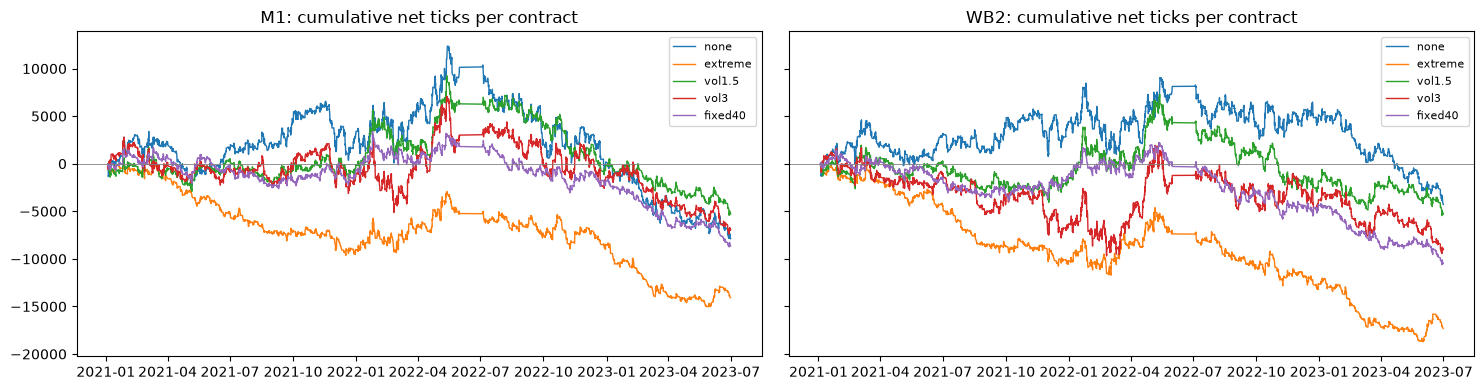

--- M1, no stop: net ticks by |burst move| quartile and by side


mean        count     
side                 -1      1    -1    1
burst_move_ticks                         
(0.999, 51.0]      0.56  -1.42   369  504
(51.0, 83.0]     -13.44 -10.55   348  532
(83.0, 134.0]    -17.54  11.09   340  523
(134.0, 1322.0]   15.96  -3.35   310  557

--- WB2, no stop: net ticks by |burst move| quartile and by side


mean        count     
side                 -1      1    -1    1
burst_move_ticks                         
(0.999, 51.0]     -1.95  -1.41   400  557
(51.0, 83.0]       0.64 -10.34   379  587
(83.0, 135.0]    -10.89   7.87   350  590
(135.0, 1322.0]   19.22  -7.29   344  594

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for i, name in enumerate(("M1", "WB2")):
    for kind in BC.stops:
        tr = TR[(name, kind)]
        if len(tr):
            ax[i].plot(pd.to_datetime(tr["entry_ts"]), tr["net_ticks"].cumsum(), lw=1, label=kind)
    ax[i].axhline(0, color="grey", lw=0.6); ax[i].set_title(f"{name}: cumulative net ticks per contract"); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "equity.png", dpi=110); plt.show()
# descriptive: net by burst size and by direction (time-stop-only rule)
for name in ("M1", "WB2"):
    tr = TR[(name, "none")]
    if len(tr) > 20:
        q = pd.qcut(tr["burst_move_ticks"].abs(), 4, duplicates="drop")
        print(f"--- {name}, no stop: net ticks by |burst move| quartile and by side")
        display(tr.groupby([q, "side"], observed=True)["net_ticks"].agg(["mean", "count"]).round(2).unstack())

## 3. Verdict

In [7]:
passed = [f"{m}/{s}" for (m, s) in G.index[G["pass"]]]
verdict = ("CANDIDATE (2026 pre-registration): " + ", ".join(passed)) if passed else "NO_EDGE"
print(verdict)
summary = {"study": "RSW 04", "engine": B.BR_VERSION, "synthetic": SYNTHETIC, "synthetic_null": SYNTH_NULL,
           "round_trip_ticks": BC.round_trip_ticks, "fits": info,
           "episodes": {k: int(len(v)) for k, v in EV.items()},
           "results": json.loads(G.reset_index().to_json(orient="records")), "verdict": verdict}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=str)
print("written", OUT / "summary.json")

NO_EDGE
written 04\summary.json
